# WP4: Invariant manifolds and application to Mars exploration mission

## Personal problem specification 

| Parameter | Value |
|-----------|-------|
| Sun/Earth Lagrange point | L2 |
| Sun/Mars Lagrange point | L2 |
| Shift in Lagrange points | 0.00100 |
| Radius Martian parking orbit | 244,444 km |
| Lightness number | 0.0300 |

## Library & constant imports

In [52]:
from constants import *

import numpy as np
import scipy 
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import pickle
import nbimporter
from IPython.display import display

from wp1 import dUdx_colinear, nablaU
from auxiliary_functions import nablaU, dUdx_colinear, hessianU, jacobian, eom

# ── Font sizes for plots (adjustable) ──────────────────────────────────────────
FONTSIZE_SMALL = 16              # Contour labels, small text
FONTSIZE_TICKS = 15              # Tick labels
FONTSIZE_AXIS_LABELS = 30        # Axis point labels
FONTSIZE_XLABEL_YLABEL = 16      # Axis label text
FONTSIZE_LEGEND = 15             # Legend and annotations
FONTSIZE_TITLE = 36              # Main titles

Importing of the eigenvalues and eigenvectors saved from the notebook for WP3. 

In [53]:
with open('eigenvalues_eigenvectors.pkl', 'rb') as f:
    eigenvalues_eigenvectors = pickle.load(f)

eigenvalues_mars_classical = eigenvalues_eigenvectors['eigenvalues_mars_classical']
eigenvectors_mars_classical = eigenvalues_eigenvectors['eigenvectors_mars_classical']

And also importing the Lagrange points position.

In [54]:
with open('lagrange_points.pkl', 'rb') as f:
    lagrange_points = pickle.load(f)

# L2_earth = lagrange_points['L2_earth']
L2_mars  = lagrange_points['L2_mars']

## Task 4.1

Computing and plotting the unstable and stable manifolds for the **classical Sun-Mars Lagrange point**, using the following parameters provided in the assignment text. 

In [55]:
earth_years = 5
tolerance = 1e-12 # absolute and relative integration tolerance
perturbation_magnitude = 1e-5 

time_span = earth_years * year_in_seconds / time_unit_sun_mars
time_span

19.11773909684742

It implies the integration of the stable and unstable equations of motion. First, the unstable one will be considered. 

### Unstable manifold

In [56]:
unstable_eigenvalue_mars = eigenvalues_mars_classical[0].real
unstable_eigenvector_mars = eigenvectors_mars_classical[:, 0].real 
print("Unstable eigenvalue:", unstable_eigenvalue_mars)
print("Unstable eigenvector:", unstable_eigenvector_mars)

Unstable eigenvalue: 2.4969462455360953
Unstable eigenvector: [-0.32680059  0.17726628 -0.8160035   0.44262437]


Once checked that the values are the one corresponding to the unstable manifold (eigenvalue with positive real part), the EOM are integrated.

In [57]:
state0_unstable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * unstable_eigenvector_mars
state0_unstable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * unstable_eigenvector_mars

sol_unstable_plus = solve_ivp(eom, [0, time_span], state0_unstable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_unstable_minus = solve_ivp(eom, [0, time_span], state0_unstable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Stable manifold

In [58]:
stable_eigenvalue_mars = eigenvalues_mars_classical[1].real
stable_eigenvector_mars = eigenvectors_mars_classical[:, 1].real 
print("Stable eigenvalue:", stable_eigenvalue_mars)
print("Stable eigenvector:", stable_eigenvector_mars)

Stable eigenvalue: -2.496946245536095
Stable eigenvector: [-0.32680059 -0.17726628  0.8160035   0.44262437]


Once checked that the values are the one corresponding to the stable manifold (eigenvalue with negative real part), the EOM are integrated. Mind that the integration interval now goes from $[0, -t]$ (the opposite as before). 

In [59]:
state0_stable_plus = np.array([L2_mars, 0.0, 0.0, 0.0]) + perturbation_magnitude * stable_eigenvector_mars
state0_stable_minus = np.array([L2_mars, 0.0, 0.0, 0.0]) - perturbation_magnitude * stable_eigenvector_mars

sol_stable_plus = solve_ivp(eom, [0, -time_span], state0_stable_plus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)
sol_stable_minus = solve_ivp(eom, [0, -time_span], state0_stable_minus, args=(mass_ratio_sun_mars,), method='DOP853', rtol=tolerance, atol=tolerance, dense_output=True)

### Plotting the results

For the plotting, the Mars parking orbit also has to be computed

In [60]:
radius_parking = radius_mars_parking_orbit / length_unit_sun_mars

Also the dimensionless distance of the Earth's orbit in the Sun-Mars system:

In [61]:
distance_earth = AU / length_unit_sun_mars

Coupling the trajectories for plotting

In [62]:
t_unstable_coupled = np.concatenate([-sol_unstable_minus.t[::-1], sol_unstable_plus.t])
y_unstable_coupled = np.concatenate([sol_unstable_minus.y[:, ::-1], sol_unstable_plus.y], axis=1)

t_stable_coupled = np.concatenate([-sol_stable_minus.t[::-1], sol_stable_plus.t])
y_stable_coupled = np.concatenate([sol_stable_minus.y[:, ::-1], sol_stable_plus.y], axis=1)

System-wide view of the manifolds:

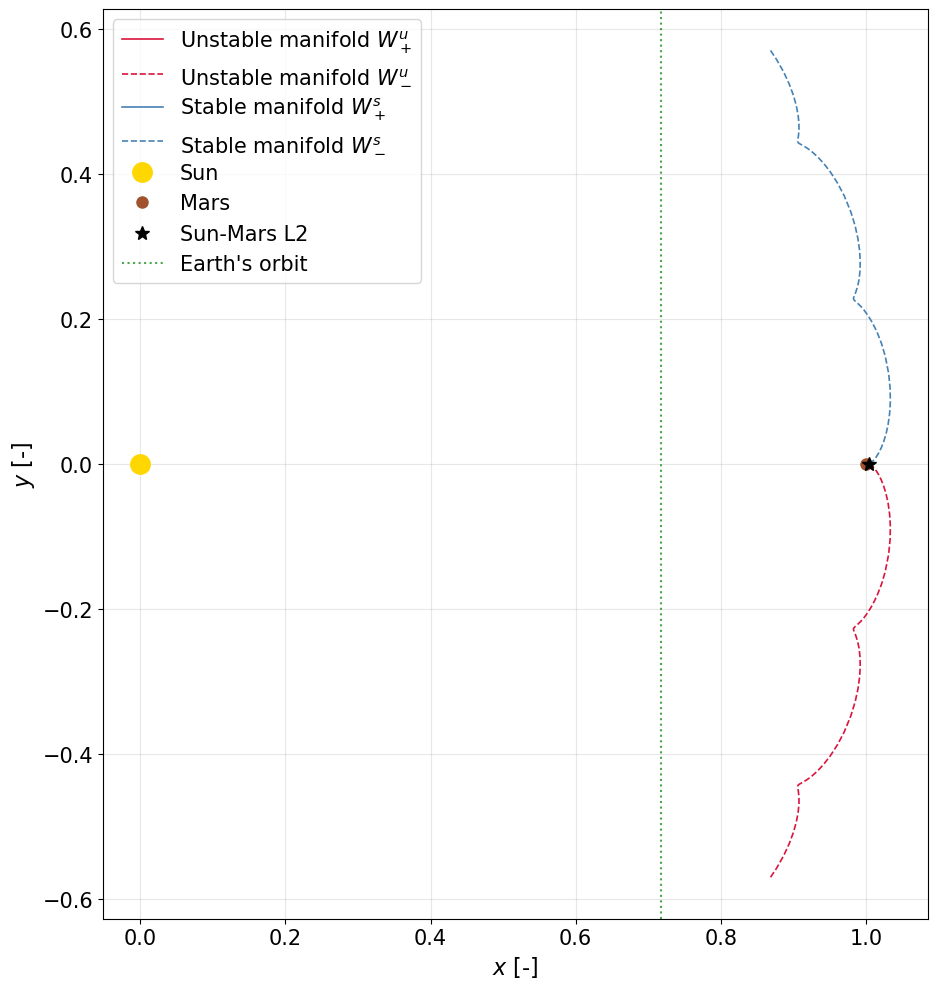

In [ ]:
# ── System-wide view ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))

# Mars position in the rotating frame (at x = 1 - mu, y = 0)
x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')

# Sun (at x = -mu, y = 0) and Mars markers
ax.plot(-mass_ratio_sun_mars, 0, 'o', color='gold', ms=14, zorder=5, label='Sun')
ax.plot(x_mars, 0, 'o', color='sienna', ms=8, zorder=5, label='Mars')

# L2 marker
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label=f'Sun-Mars L2')

# Earth's orbital distance marker
ax.axvline(x=distance_earth, color='green', lw=1.5, ls=':', alpha=0.7, label="Earth's orbital distance")

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('System-wide view — Sun-Mars invariant manifolds', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_system_wide.pdf', dpi=150, bbox_inches='tight')
plt.show()

Close-up view of the projections of the manifolds: 

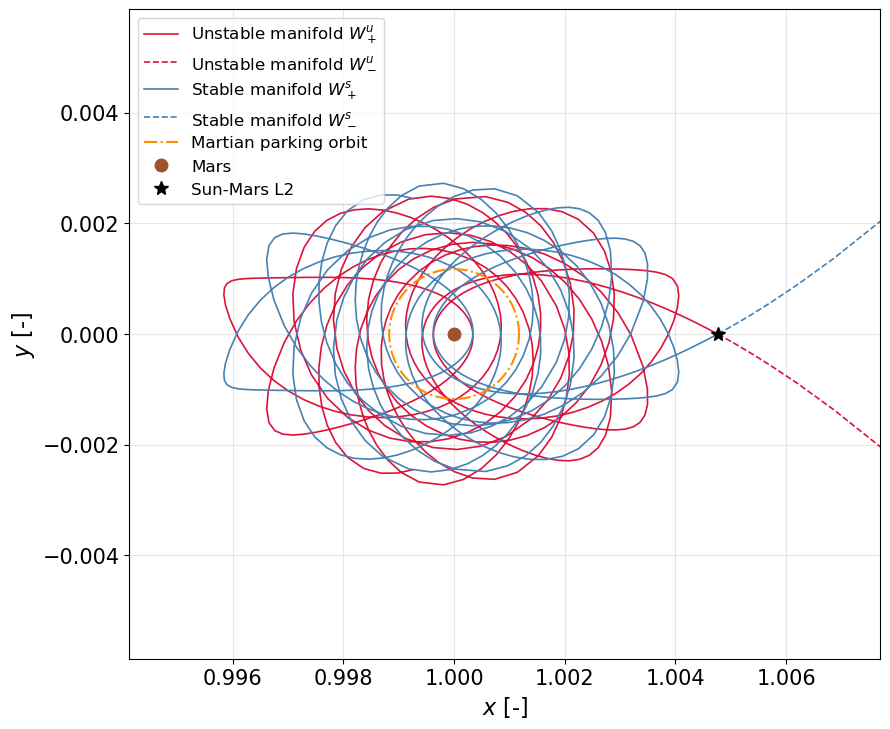

In [64]:
# ── Close-up view near Mars ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 9))

x_mars = 1 - mass_ratio_sun_mars

# Manifold trajectories
ax.plot(sol_unstable_plus.y[0], sol_unstable_plus.y[1],
        color='crimson', lw=1.2, label='Unstable manifold $W^u_+$')
ax.plot(sol_unstable_minus.y[0], sol_unstable_minus.y[1],
        color='crimson', lw=1.2, ls='--', label='Unstable manifold $W^u_-$')
ax.plot(sol_stable_plus.y[0], sol_stable_plus.y[1],
        color='steelblue', lw=1.2, label='Stable manifold $W^s_+$')
ax.plot(sol_stable_minus.y[0], sol_stable_minus.y[1],
        color='steelblue', lw=1.2, ls='--', label='Stable manifold $W^s_-$')
        
# Martian parking orbit (circle of radius radius_parking centred on Mars)
theta = np.linspace(0, 2 * np.pi, 1000)
ax.plot(x_mars + radius_parking * np.cos(theta),
        radius_parking * np.sin(theta),
        color='darkorange', lw=1.5, ls='-.', label='Martian parking orbit')

# Mars and L2 markers
ax.plot(x_mars, 0, 'o', color='sienna', ms=9, zorder=5, label='Mars')
ax.plot(L2_mars, 0, '*', color='black', ms=10, zorder=5, label='Sun-Mars L2')

# Set axis limits centred on Mars with some margin
margin = 5 * radius_parking
ax.set_xlim(x_mars - margin, L2_mars + margin * 0.5)
ax.set_ylim(-margin, margin)

ax.set_xlabel(r'$x$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
ax.set_ylabel(r'$y$ [-]', fontsize=FONTSIZE_XLABEL_YLABEL)
# ax.set_title('Close-up view — manifold structure near Mars', fontsize=FONTSIZE_SMALL)
ax.set_aspect('equal')
ax.tick_params(labelsize=FONTSIZE_TICKS)
ax.legend(fontsize=FONTSIZE_LEGEND-3, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/wp4_manifolds_closeup.pdf', dpi=150, bbox_inches='tight')
plt.show()

In [65]:
x_mars

0.9999996772845003